In [19]:
# import packages

import yfinance as yf
import numpy as np
import pandas as pd 
import statsmodels.api as sm 
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint

In [20]:
# Download stock data for PepsiCo and Coca-Cola
tickers = ['PEP', 'KO']
data = yf.download(tickers, start='2015-01-01', end='2023-01-01')['Close']

# Preview the data
data.head()

/tmp/ipykernel_9610/746400271.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start='2015-01-01', end='2023-01-01')['Close']
[*********************100%***********************]  2 of 2 completed


Ticker,KO,PEP
Date,,
2015-01-02,30.222622,69.219124
2015-01-05,30.222622,68.698715
2015-01-06,30.452114,68.178329
2015-01-07,30.832241,70.171913
2015-01-08,31.205172,71.447281


To assess whether the price series of PepsiCo (PEP) and Coca-Cola (KO) are cointegrated,
we use the cointegration test from statsmodels, which internally applies the Augmented Dickey-Fuller (ADF) test
to the residuals of a linear combination of the two series.
The test returns a test statistic (score) and a p-value:
- The score (test statistic) indicates how strongly the null hypothesis (no cointegration) can be rejected.
- The p-value helps us determine statistical significance; a small p-value (typically < 0.05) suggests the series are cointegrated.

In [21]:
score, p_value, crit_value = coint(data['PEP'], data['KO'])
print('Cointegration test score:', score)
print('Cointegration test p-value:', p_value)

Cointegration test score: -3.828505598019551
Cointegration test p-value: 0.01241476851345599


In [22]:
if p_value < 0.05:
    print("The series are cointegrated.")
else:
    print("The series are not cointegrated.")

The series are cointegrated.


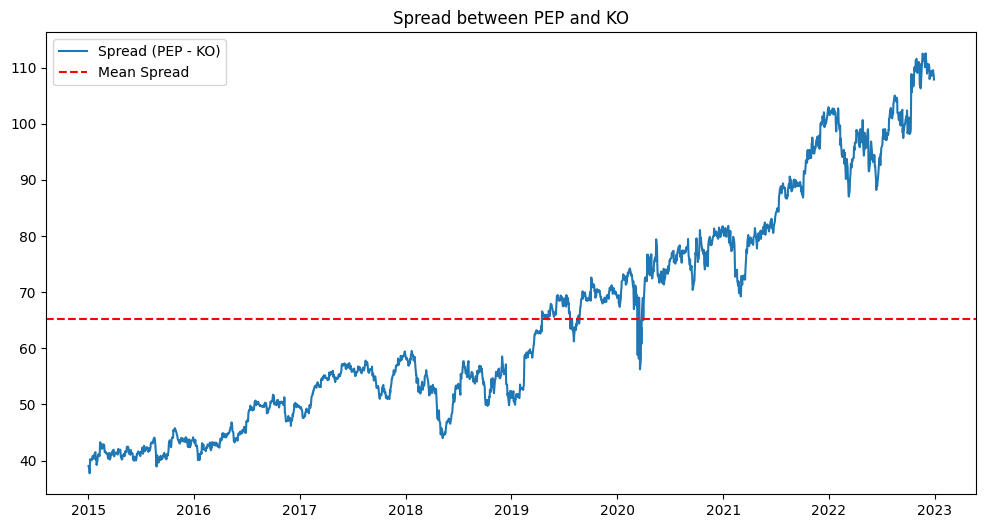

In [23]:
data['Spread'] = data['PEP'] - data['KO']


plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Spread'], label='Spread (PEP - KO)')
plt.axhline(data['Spread'].mean(), color='red', linestyle='--', label='Mean Spread')
plt.title('Spread between PEP and KO')
plt.legend()
plt.show()

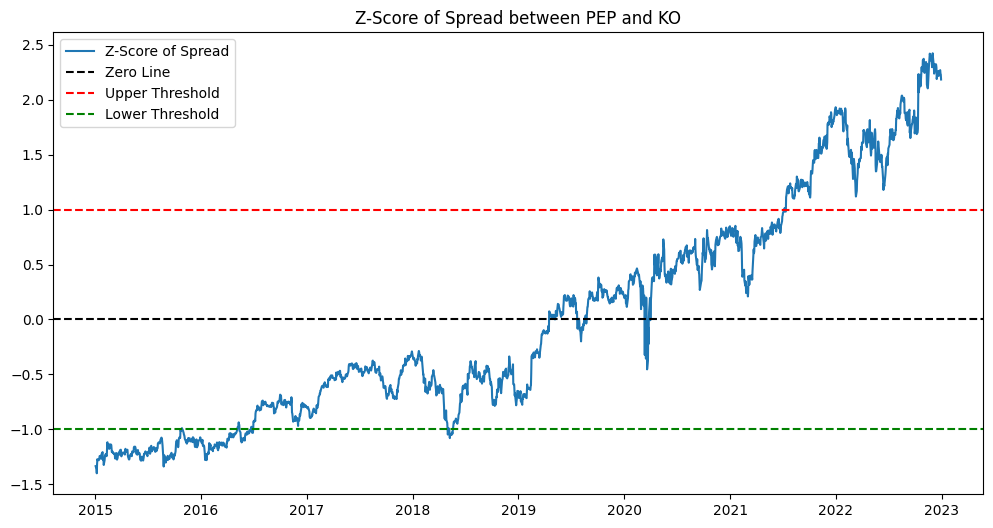

In [24]:
data['Z-Score'] = (data['Spread'] - data['Spread'].mean()) / data['Spread'].std()

plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Z-Score'], label='Z-Score of Spread')
plt.axhline(0, color='black', linestyle='--', label='Zero Line')
plt.axhline(1, color='red', linestyle='--', label='Upper Threshold')
plt.axhline(-1, color='green', linestyle='--', label='Lower Threshold')
plt.title('Z-Score of Spread between PEP and KO')
plt.legend()
plt.show()

In [25]:
data['Long'] = data['Z-Score'] < -1
data['Short'] = data['Z-Score'] > 1
data['Exit'] = (data['Z-Score'] > -0.5) & (data['Z-Score'] < 0.5)

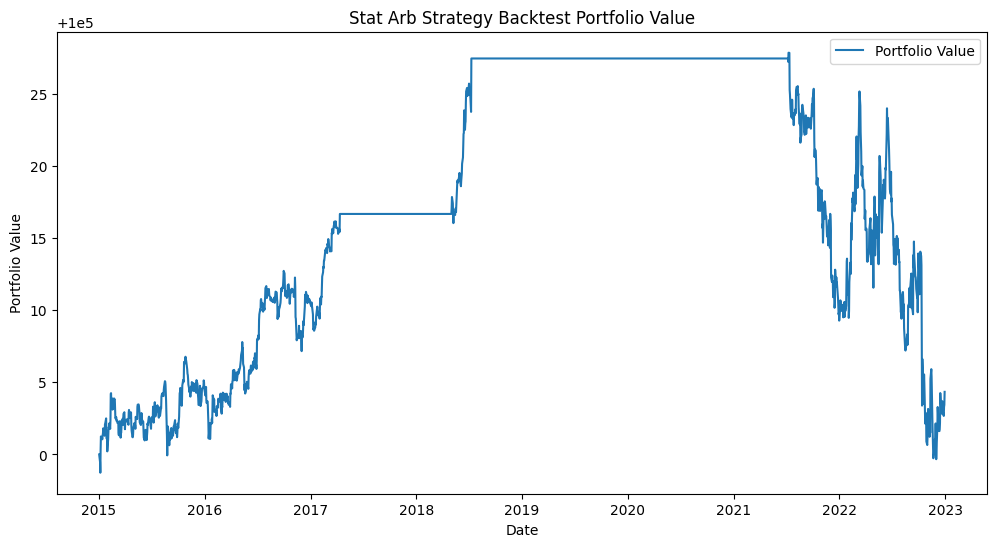

In [27]:
# Simple backtest for a statistical arbitrage strategy using the 'Long', 'Short', and 'Exit' signals

initial_capital = 100000
capital = initial_capital
position = 0  # +1 for long, -1 for short, 0 for no position
portfolio_values = []
returns = []
positions = []

for i in range(len(data)):
    row = data.iloc[i]
    price_pep = row['PEP']
    price_ko = row['KO']

    # Entry signals
    if row['Long'] and position == 0:
        position = 1  # Enter long spread: Long PEP, Short KO
        entry_pep = price_pep
        entry_ko = price_ko
    elif row['Short'] and position == 0:
        position = -1  # Enter short spread: Short PEP, Long KO
        entry_pep = price_pep
        entry_ko = price_ko

    # Exit signal
    if row['Exit'] and position != 0:
        if position == 1:
            pnl = (price_pep - entry_pep) - (price_ko - entry_ko)
        elif position == -1:
            pnl = (entry_pep - price_pep) - (entry_ko - price_ko)
        capital += pnl
        position = 0

    # Track portfolio value (mark-to-market)
    if position == 1:
        mtm = capital + (price_pep - entry_pep) - (price_ko - entry_ko)
    elif position == -1:
        mtm = capital + (entry_pep - price_pep) - (entry_ko - price_ko)
    else:
        mtm = capital

    portfolio_values.append(mtm)
    positions.append(position)
    if i == 0:
        returns.append(0)
    else:
        returns.append((mtm - portfolio_values[i-1]) / portfolio_values[i-1])

# Add results to DataFrame
data['Portfolio Value'] = portfolio_values
data['Returns'] = returns
data['Cumulative Returns'] = np.cumsum(returns)
data['Position'] = positions

# Display performance
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Portfolio Value'], label='Portfolio Value')
plt.title('Stat Arb Strategy Backtest Portfolio Value')
plt.xlabel('Date')
plt.ylabel('Portfolio Value')
plt.legend()
plt.show()

In [32]:
data['Portfolio Value']  # Final portfolio value

Date
2015-01-02    100000.000000
2015-01-05     99999.479591
2015-01-06     99998.729713
2015-01-07    100000.343170
2015-01-08    100001.245607
                  ...      
2022-12-23    100003.057987
2022-12-27    100002.671535
2022-12-28    100003.297195
2022-12-29    100003.437103
2022-12-30    100004.340927
Name: Portfolio Value, Length: 2014, dtype: float64